In [1]:
import pandas as pd
from sklearn import preprocessing
from sklearn.model_selection import cross_val_score, train_test_split
encoder = preprocessing.LabelEncoder()

data = pd.read_excel("C_Dtst_Final_Data_Full_14-08-26.xlsx")
#data = data.iloc[:1522]
data['Metal_Ion'] = encoder.fit_transform(data['Metal_Ion'])
data['Linker'] = encoder.fit_transform(data['Linker'])
#data['Gel'] = encoder.fit_transform(data['Gel'])

data.pop('Time_m')
data.pop('doi')
data.pop('mol')
data.pop('smiles')
#data = data.sample(frac=1)


#data.to_csv("C_Dtst_cleaned.csv")
data.head()

,Unnamed: 0,Unnamed: 1,Title,Gel,pH,Metal_Ion,Metal_Conc,Linker,Linker_Conc,Cytidine_Conc,DS,Vol,Alginate
0,NaN,NaN,Nucleoside-Derived Metallohydrogel Induces Cel...,1,5.5,0,0.490,7,0.123,0.123,0.0,1.0,0.0
1,NaN,NaN,NaN,1,5.5,0,0.246,7,0.123,0.123,0.0,1.0,0.0
2,NaN,NaN,NaN,1,5.5,0,0.164,7,0.123,0.123,0.0,1.0,0.0
3,NaN,NaN,NaN,1,5.5,0,0.123,7,0.123,0.123,0.0,1.0,0.0
4,NaN,NaN,NaN,0,2.5,0,0.490,7,0.123,0.123,0.0,1.0,0.0


In [2]:
X = data.loc[:,'pH':'Alginate']
y = round(data.Gel)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42,shuffle=True)
print(X_train.shape, y.shape)
X.head()

(1361, 9) (1945,)


,pH,Metal_Ion,Metal_Conc,Linker,Linker_Conc,Cytidine_Conc,DS,Vol,Alginate
0,5.5,0,0.490,7,0.123,0.123,0.0,1.0,0.0
1,5.5,0,0.246,7,0.123,0.123,0.0,1.0,0.0
2,5.5,0,0.164,7,0.123,0.123,0.0,1.0,0.0
3,5.5,0,0.123,7,0.123,0.123,0.0,1.0,0.0
4,2.5,0,0.490,7,0.123,0.123,0.0,1.0,0.0


In [122]:
import os
import gc
import multiprocessing

# 1. Kill any lingering parallel processing pools
try:
    multiprocessing.active_children()
    for p in multiprocessing.active_children():
        p.terminate()
except Exception:
    pass

# 2. Force CPU backend libraries to single-threaded mode to prevent deadlocks
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# 3. Clean Python memory
gc.collect()

print("CPU thread pools and background queues cleared.")

CPU thread pools and background queues cleared.


In [10]:
import os
import sqlite3

# Disable IPython history database logging to prevent session lock warnings
os.environ["IPYTHONDIR"] = "/tmp/.ipython"

# Alternatively, if you want to clear or silence the sqlite history lock directly:
try:
    from IPython import get_ipython
    ipython = get_ipython()
    if ipython:
        ipython.history_manager.enabled = False
except Exception:
    pass

print("IPython history database logging disabled.")

IPython history database logging disabled.


In [5]:
import optuna
import xgboost as xgb
from sklearn.model_selection import cross_val_score, train_test_split
from xgboost import XGBClassifier
from sklearn import metrics

# Create the training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42,shuffle=True)
def objective_clf(trial):
    # Define the search space
    params = {
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 10),
        #'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10),
        'device':'cpu',
        'random_state': 42
    }
   
    clf_1 = xgb.XGBClassifier(**params)

    clf_1.fit(X_train, y_train)
    y_pred_1 = clf_1.predict(X_test)

    p_m1 = clf_1.predict_proba(X_test)[:, 1]
    fpr, tpr, roc_thresh = metrics.roc_curve(y_test, p_m1)
    pr, rcl, prc_thresh = metrics.precision_recall_curve(y_test, p_m1)


    # Compute the accuracy of the predictions: accuracy
    accuracy_xgb = metrics.accuracy_score(y_test,y_pred_1)#float(np.sum(y_pred_4==y_test))/y_test.shape[0]
    balanced_acc = metrics.balanced_accuracy_score(y_test,y_pred_1)
    avg_prc = metrics.average_precision_score(y_test,y_pred_1)
    auc_score_xgb = metrics.roc_auc_score(y_test,y_pred_1)
    F1_xgb = metrics.f1_score(y_test,y_pred_1)
    recall_xgb = metrics.recall_score(y_test,y_pred_1)
    precision_xgb = metrics.recall_score(y_test,y_pred_1)

    auroc = metrics.auc(fpr, tpr)
    auprc = metrics.auc(rcl, pr)

    roc_dict = {
        "fpr": fpr.tolist(),      # Convert to list for easier serialization/storage
        "tpr": tpr.tolist(),
        "pr": pr.tolist(),
        "rcl": rcl.tolist(),
        "roc_threshold": roc_thresh.tolist(),
        "prc_threshold": prc_thresh.tolist()
    }

    metrics_dict = {
        "roc": auroc,
        "aprc": auprc,
        "acc": accuracy_xgb,
        "prc": avg_prc,
        "F1": F1_xgb,
        "rcl": recall_xgb,
    }
    trial.set_user_attr("roc_data", roc_dict)
    trial.set_user_attr("metrics_data", metrics_dict)
    # Use cross-validation to get a robust score
    # cross validation will wreck optuna due to multi threading
    #score = cross_val_score(clf_1, X, y, n_jobs=-1, cv=3).mean()
    return accuracy_xgb

all_roc_results = {}
metric_results = {}
def store_roc_callback(study, trial):
    # Retrieve the dict we saved in the objective function
    if "roc_data" in trial.user_attrs:
        all_roc_results[trial.number] = trial.user_attrs["roc_data"]
        metric_results[trial.number] = trial.user_attrs["metrics_data"]
       
# Run the optimization
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective_clf, n_trials=150, gc_after_trial=True, callbacks=[store_roc_callback]) #callback function will store the roc curve data for each trial

print("Best params:", study.best_params)

[I 2026-10-05 16:20:10,354] A new study created in memory with name: no-name-46547a30-fcd0-44af-a8f2-8922abfa79d5
[I 2026-10-05 16:20:10,464] Trial 0 finished with value: 0.8613013698630136 and parameters: {'max_depth': 5, 'gamma': 4.75357153204958, 'reg_lambda': 7.319939418114051, 'learning_rate': 0.07661100707771368, 'n_estimators': 240, 'subsample': 0.5779972601681014, 'colsample_bytree': 0.5290418060840998, 'scale_pos_weight': 8.795585311974417, 'max_delta_step': 6}. Best is trial 0 with value: 0.8613013698630136.
[I 2026-10-05 16:20:10,809] Trial 1 finished with value: 0.8921232876712328 and parameters: {'max_depth': 8, 'gamma': 0.10292247147901223, 'reg_lambda': 9.699098521619943, 'learning_rate': 0.16967533607196555, 'n_estimators': 291, 'subsample': 0.5909124836035503, 'colsample_bytree': 0.5917022549267169, 'scale_pos_weight': 3.7381801866358395, 'max_delta_step': 5}. Best is trial 1 with value: 0.8921232876712328.
[I 2026-10-05 16:20:11,182] Trial 2 finished with value: 0.871

Best params: {'max_depth': 8, 'gamma': 1.1299761213834059, 'reg_lambda': 1.3894093192551917, 'learning_rate': 0.015208971858465335, 'n_estimators': 644, 'subsample': 0.9907848179001805, 'colsample_bytree': 0.7416050972716348, 'scale_pos_weight': 1.7402900568407569, 'max_delta_step': 8}


In [7]:
metrics_data =  pd.DataFrame(metric_results)
mtrx = metrics_data.T.sort_values(by='acc',ascending=False) #head(50)
mtrx.to_csv('optimized_xgbt_metrics.csv')

In [231]:
# 1. Get all trials
all_trials = study.trials

# 2. Sort them by 'value' (your objective metric)
# We use reverse=True because we used direction='maximize'
sorted_trials = sorted(all_trials, key=lambda t: t.value if t.value is not None else -float('inf'), reverse=True)

# 3. Print the top 5
for i, trial in enumerate(sorted_trials[:5]):
    print(f"Rank {i+1}: Trial {trial.number} with Score {trial.value:.4f}")

Rank 1: Trial 94 with Score 0.9092
Rank 2: Trial 98 with Score 0.9092
Rank 3: Trial 103 with Score 0.9092
Rank 4: Trial 59 with Score 0.9075
Rank 5: Trial 72 with Score 0.9075


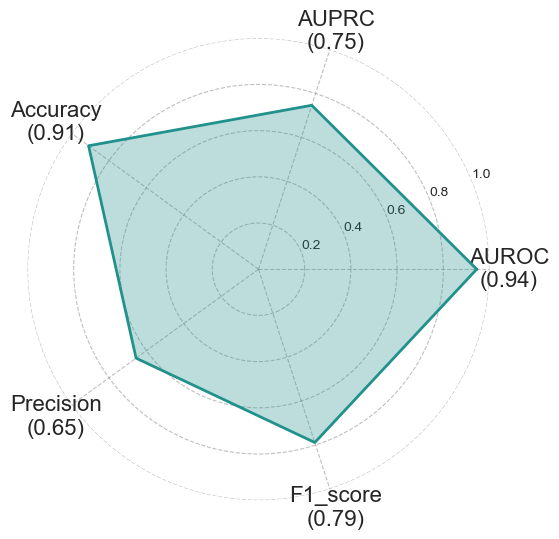

In [235]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Apply Seaborn styling
sns.set_style("white")

trial_num = 94
# 2. Prepare data
values = metrics_data.T.iloc[trial_num].values.tolist()
labels = [f'AUROC\n({round(metrics_data.T.iloc[trial_num].values[0],2)})',
          f'AUPRC\n({round(metrics_data.T.iloc[trial_num].values[1],2)})',
          f'Accuracy\n({round(metrics_data.T.iloc[trial_num].values[2],2)})',
          f'Precision\n({round(metrics_data.T.iloc[trial_num].values[3],2)})',
          f'F1_score\n({round(metrics_data.T.iloc[trial_num].values[4],2)})'
         ]

num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# Close the loop
values_closed = values + [values[0]]
angles_closed = angles + [angles[0]]

# 3. Initialize the plot
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

# 4. Use Seaborn color palette for the fill
palette = sns.color_palette("viridis", 1)
ax.plot(angles_closed, values_closed, color=palette[0], linewidth=2)
ax.fill(angles_closed, values_closed, color=palette[0], alpha=0.3)

# 5. Styling with Seaborn-like touches
ax.set_xticks(angles)
ax.set_xticklabels(labels, fontsize=16)
ax.set_ylim(0, 1)
ax.set_frame_on(False)
ax.grid(color='grey', linestyle='--', alpha=0.5)
plt.savefig('figure/xgb_optimize/Metrics.png',dpi=600,transparent=False,bbox_inches='tight', pad_inches=0)
plt.show()

In [ ]:
Best params: {'max_depth': 7, 'gamma': 1.6589037684246246, 'reg_lambda': 3.081746085285214, 'learning_rate': 0.12218608306596028, 'n_estimators': 335, 'subsample': 0.809484768249986, 'colsample_bytree': 0.7138695333071385, 'scale_pos_weight': 3.673880554372252, 'max_delta_step': 9}

In [234]:
from matplotlib import font_manager as fm
import matplotlib.pyplot as plt

fm.fontManager.addfont('Arial.ttf')
plt.rcParams["font.family"] = 'Arial'

/tmp/ipykernel_3156378/2600802692.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')


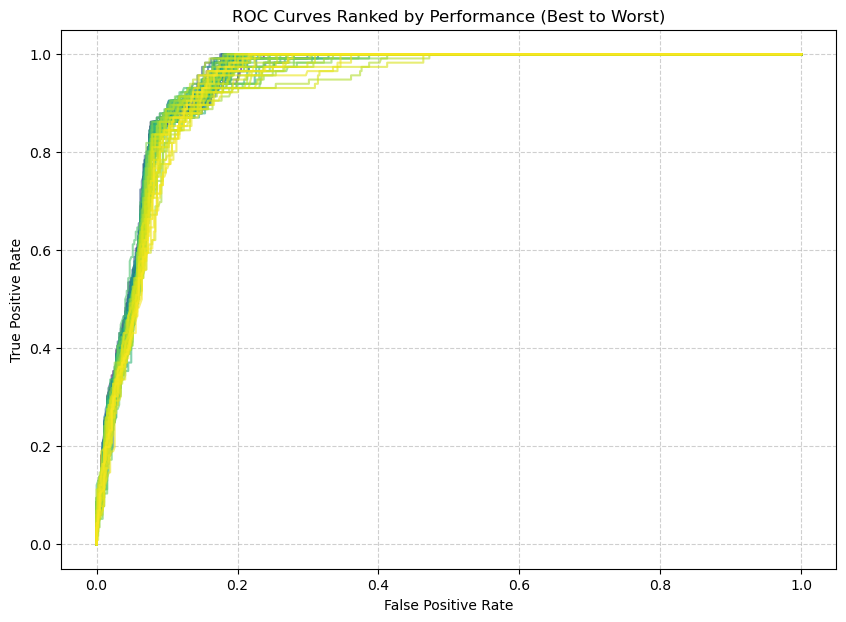

In [22]:
import matplotlib.cm as cm

# 1. Sort the trials based on their objective value (best to worst)
# Assuming direction='maximize', so reverse=True
sorted_trials = sorted(study.trials, 
                       key=lambda t: t.value if t.value is not None else -float('inf'), 
                       reverse=True)

plt.figure(figsize=(10, 7))
cmap = cm.get_cmap('viridis')

# 2. Iterate through the sorted trials
for rank, trial in enumerate(sorted_trials):
    # Skip if the trial doesn't have ROC data
    if trial.number not in all_roc_results:
        continue
        
    roc_data = all_roc_results[trial.number]
    
    # 3. Map color to rank (best = rank 0, worst = rank 149)
    # color will range from 0 (best) to 1 (worst)
    color = cmap(rank / len(sorted_trials))
    
    plt.plot(roc_data['fpr'], 
             roc_data['tpr'], 
             linewidth=1.5, 
             alpha=0.6, 
             color=color, 
             label=f'Rank {rank+1} (Trial {trial.number})')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Ranked by Performance (Best to Worst)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

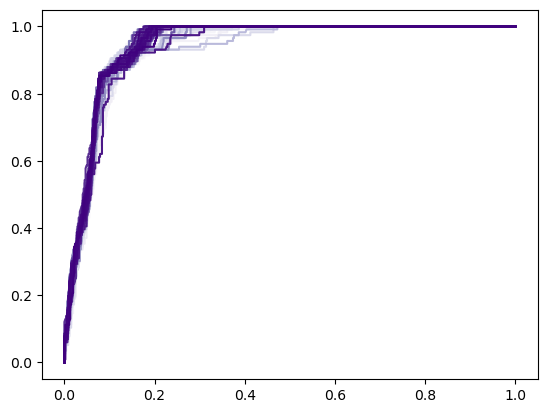

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc

import matplotlib
auc_val_lst = []


cmap = plt.get_cmap('Purples')
for i in range(150):
    color = cmap(i / 150)
    roc_data = all_roc_results[i]
    plt.plot(roc_data['fpr'], roc_data['tpr'], linewidth = 1.5, color=color, label=f'Trial {i}')

    auc_val = auc(roc_data['fpr'], roc_data['tpr'])
    auc_val_lst.append(auc_val)

#plt.legend()
plt.show()

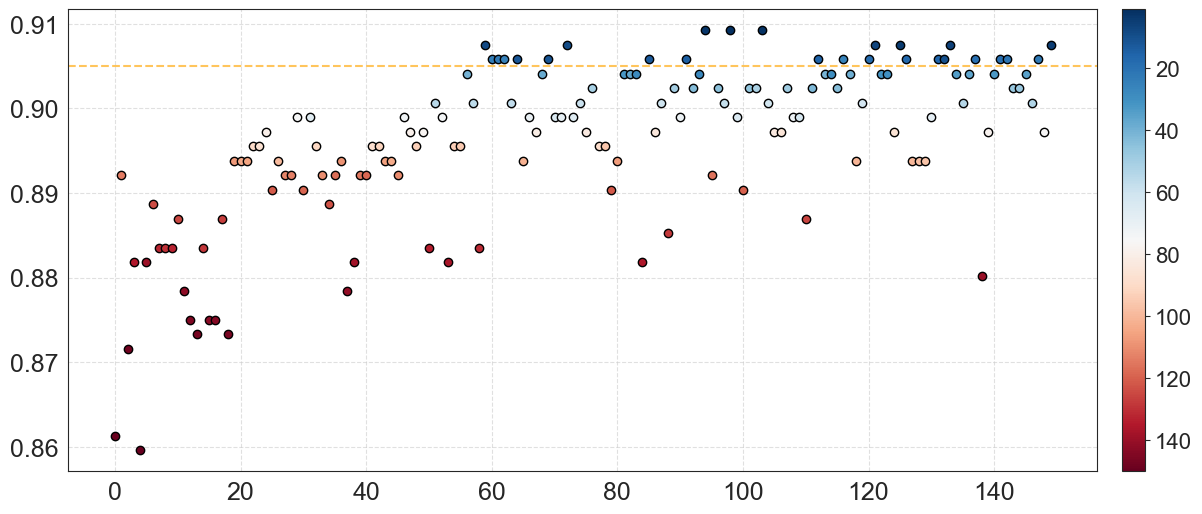

In [236]:
metrics_data =  pd.DataFrame(metric_results)
metrics_acc = metrics_data.T
#print(metrics_acc.acc)
acc_lst = metrics_acc.acc
acc_ranks = np.argsort(np.argsort(acc_lst)) #np.array(metrics_acc.index)
inverted_ranks = (len(auc_val_lst) - 1) - acc_ranks + 1

norm = Normalize(vmin=1, vmax=len(acc_lst))
normalized_ranks = norm(inverted_ranks)
#print(acc_ranks)

plt.figure(figsize=(16, 6))
cmap = plt.get_cmap('RdBu_r') # Ensure this matches your desired color direction

for i in range(150):
    acc_val = acc_lst[i]
    color = cmap(normalized_ranks[i])
    plt.scatter(i, acc_val, edgecolors='k', color=color)


plt.axhline(y=0.905, color='orange', linestyle='--', 
            linewidth=1.5,alpha=0.64 ,label='Threshold')

# 4. Colorbar with inverted mapping
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=2e-2)

#cbar.set_label('Trial Rank (1 = Best, 150 = Worst)', fontsize=14)
cbar.ax.invert_yaxis()
cbar.ax.tick_params(labelsize=16)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tick_params(axis='y',which='both',labelsize=18)
plt.tick_params(axis='x',which='both',labelsize=18)
plt.savefig('figure/xgb_optimize/acc_trials.png',dpi=600,transparent=False,bbox_inches='tight', pad_inches=0)
plt.show()

[145 121 127 130 134  34 137  79 146  38 142 133 138 148 136 128 144 119
 143 118  68 114  86  77 104  99  25 122  89 113  58 120 131 100 106 140
  39 150  51 115  64  88 107 132  66 110  78  98 126  82 123 101  93 135
 129 109  16  74 149  41  71  54  50 103  85  63  26   9  91 102  81 108
  31  56  48  21  97  69  12 141 117  90  11  32 139  92 125  61  94   3
  70  44  19  65  30 111   2  28  40  17  10  76   8  29   4  95   6  73
 112  24 124  59  53  80  14  36  49  60 116  15   7  67  75  46  43  18
  33  23   5  96  13  52  55  57  47 105  62  87 147  35  45  37  20  22
  27  84  83   1  42  72]


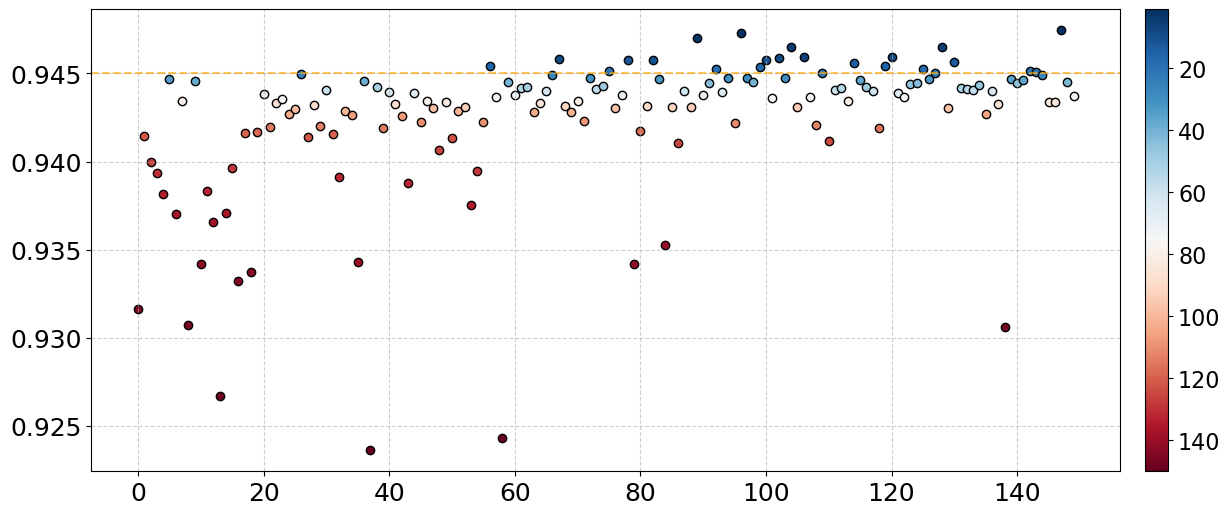

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize

# 1. Calculate ranks (0 = Worst, 149 = Best)
raw_ranks = np.argsort(np.argsort(auc_val_lst))

# 2. Invert ranks (1 = Best, 150 = Worst)
# We subtract the raw rank from the max rank (149) and add 1
inverted_ranks = (len(auc_val_lst) - 1) - raw_ranks + 1

# 3. Normalize for the colormap (0 to 1)
# Note: Since we want 'Best' to have a specific color (like deep blue), 
# we normalize based on the new inverted scale.
norm = Normalize(vmin=1, vmax=len(auc_val_lst))
normalized_ranks = norm(inverted_ranks)
print(inverted_ranks)

plt.figure(figsize=(16, 6))
cmap = plt.get_cmap('RdBu_r') # Ensure this matches your desired color direction

for i in range(150):
    auc_val = auc_val_lst[i]
    color = cmap(normalized_ranks[i])
    plt.scatter(i, auc_val, edgecolors='k', color=color)


plt.axhline(y=0.945, color='orange', linestyle='--', 
            linewidth=1.5,alpha=0.64 ,label='Threshold')

# 4. Colorbar with inverted mapping
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=2e-2)

#cbar.set_label('Trial Rank (1 = Best, 150 = Worst)', fontsize=14)
cbar.ax.invert_yaxis()
cbar.ax.tick_params(labelsize=16)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tick_params(axis='y',which='both',labelsize=18)
plt.tick_params(axis='x',which='both',labelsize=18)
plt.savefig('figure/xgb_optimize/auc_trials.png',dpi=600,transparent=False,bbox_inches='tight', pad_inches=0)
plt.show()

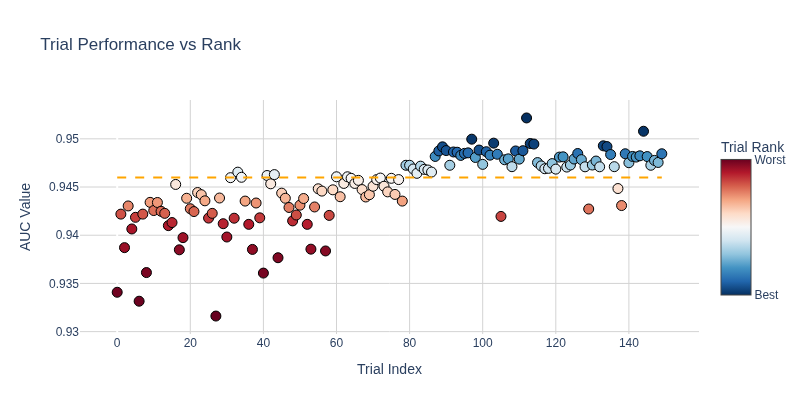

In [189]:
import plotly.graph_objects as go
import numpy as np

# Assuming you have:
# auc_val_lst: list of AUC values
# normalized_ranks: list/array of normalized ranks

fig = go.Figure()

# 1. Add the scatter plot
fig.add_trace(go.Scatter(
    x=list(range(150)),
    y=auc_val_lst,
    mode='markers',
    marker=dict(
        size=10,
        color=normalized_ranks,      # Uses the normalized values
        colorscale='RdBu_r',         # Equivalent to cmap 'RdBu_r'
        colorbar=dict(
            title='Trial Rank',
            tickvals=[0, 1],         # Mapping normalized values back to labels
            ticktext=['Best', 'Worst'],
            len=0.75
        ),
        line=dict(width=1, color='black') # edgecolors='k'
    ),
    name='Trials'
))

# 2. Add the threshold line
fig.add_shape(
    type="line",
    x0=0, y0=0.946, x1=149, y1=0.946,
    line=dict(color="orange", width=2, dash="dash"),
)

# 3. Layout settings
fig.update_layout(
    title='Trial Performance vs Rank',
    xaxis=dict(title='Trial Index', gridcolor='lightgray'),
    yaxis=dict(title='AUC Value', gridcolor='lightgray'),
    plot_bgcolor='white',
    width=1000,
    height=400
)

fig.show()

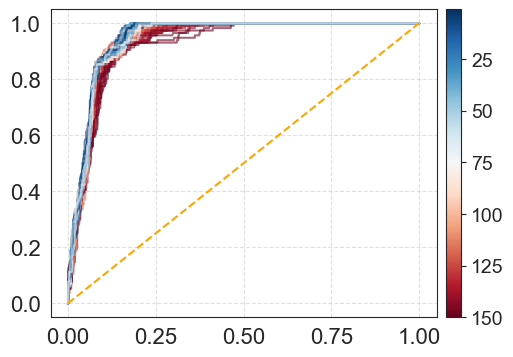

In [246]:
# 1. Calculate ranks (0 = Worst, 149 = Best)
raw_ranks = np.argsort(np.argsort(auc_val_lst))

# 2. Invert ranks (1 = Best, 150 = Worst)
# We subtract the raw rank from the max rank (149) and add 1
inverted_ranks = (len(auc_val_lst) - 1) - raw_ranks + 1

# 3. Normalize for the colormap (0 to 1)
# Note: Since we want 'Best' to have a specific color (like deep blue), 
# we normalize based on the new inverted scale.
norm = Normalize(vmin=1, vmax=len(auc_val_lst))
normalized_ranks = norm(inverted_ranks)
    
cmap = plt.get_cmap('RdBu_r')
plt.figure(figsize=(6, 4))

    # 3. Plotting loop
for i in range(len(all_roc_results)):
    color = cmap(normalized_ranks[i])
    roc_data = all_roc_results[i]
        
        # Accessing data safely
    plt.plot(roc_data['fpr'], roc_data['tpr'], 
                 linewidth=1.5, color=color, alpha=0.6)

plt.grid(True, linestyle='--', alpha=0.6)
plt.plot([0, 1], [0, 1], color='orange', linestyle='--')
plt.tick_params(axis='y',which='both',labelsize=16)
plt.tick_params(axis='x',which='both',labelsize=16)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=2e-2)
cbar.ax.invert_yaxis()
cbar.ax.tick_params(labelsize=14)

#plt.axvline(x=0.5, color='red', linestyle='--') # Example vertical line
plt.savefig('figure/xgb_optimize/auroc_trials.png',dpi=600,transparent=False,bbox_inches='tight', pad_inches=0)
plt.show()

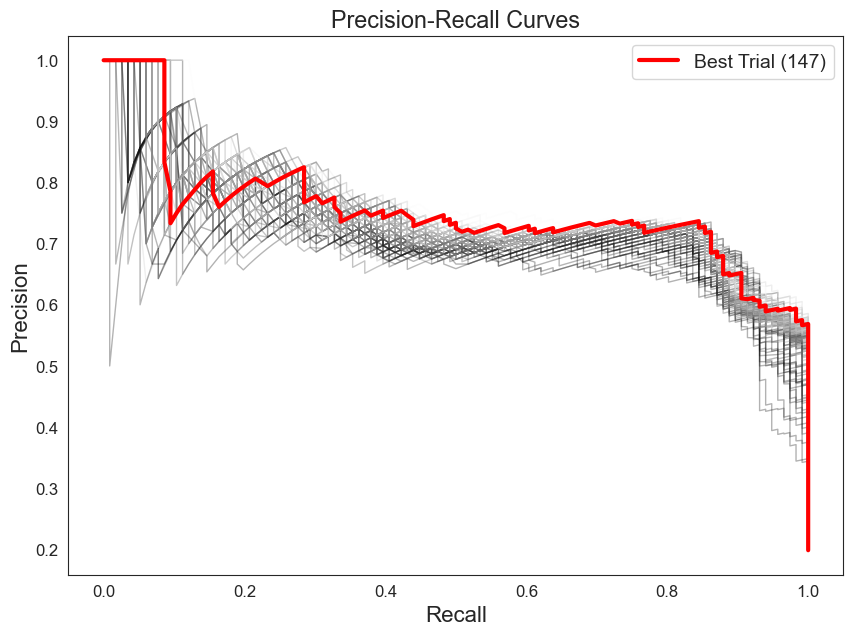

In [247]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Identify the index of the best trial
best_trial_idx = np.argmax(auc_val_lst)

# 2. Setup Plot
plt.figure(figsize=(10, 7))
cmap = plt.get_cmap('gray_r')

# 3. Plot all trials in the background
for i in range(len(all_roc_results)):
    # Skip the best trial for now, we plot it last to bring it to the front
    if i == best_trial_idx:
        continue
        
    roc_data = all_roc_results[i]
    # Use normalized ranks for subtle styling of background lines
    color = cmap(normalized_ranks[i])
    
    # Trim data to match lengths (as discussed previously)
    min_len = min(len(roc_data['rcl']), len(roc_data['pr']))
    
    plt.plot(roc_data['rcl'][:min_len], roc_data['pr'][:min_len], 
             linewidth=1, color=color, alpha=0.3)

# 4. Plot the BEST trial distinctly
best_data = all_roc_results[best_trial_idx]
plt.plot(best_data['rcl'], best_data['pr'], 
         linewidth=3, color='red', label=f'Best Trial ({best_trial_idx})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend()
plt.show()

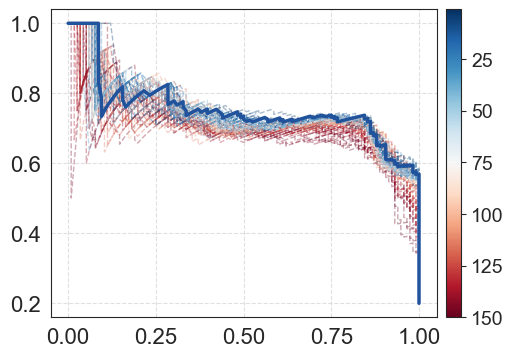

In [248]:
# 1. Calculate ranks (0 = Worst, 149 = Best)
raw_ranks = np.argsort(np.argsort(auc_val_lst))

# 2. Invert ranks (1 = Best, 150 = Worst)
# We subtract the raw rank from the max rank (149) and add 1
inverted_ranks = (len(auc_val_lst) - 1) - raw_ranks + 1

# 3. Normalize for the colormap (0 to 1)
# Note: Since we want 'Best' to have a specific color (like deep blue), 
# we normalize based on the new inverted scale.
norm = Normalize(vmin=1, vmax=len(auc_val_lst))
normalized_ranks = norm(inverted_ranks)

# Identify the index of the best trial
best_trial_idx = np.argmax(auc_val_lst)

cmap = plt.get_cmap('RdBu_r')
plt.figure(figsize=(6, 4))

    # 3. Plotting loop
for i in range(len(all_roc_results)):
    color = cmap(normalized_ranks[i])
    roc_data = all_roc_results[i]

    min_len = min(len(roc_data['rcl']), len(roc_data['pr']))
        
        # Accessing data safely
    plt.plot(roc_data['rcl'], roc_data['pr'], 
                 linewidth=1, color=color,linestyle='--', alpha=0.35)

best_data = all_roc_results[best_trial_idx]

#plt.scatter(best_data['rcl'], best_data['pr'], 
#         linewidth=1.5, color='#3A8DC2', marker="D")

plt.plot(best_data['rcl'], best_data['pr'], 
         linewidth=2.5, color='#21539C')

plt.tick_params(axis='y',which='both',labelsize=16)
plt.tick_params(axis='x',which='both',labelsize=16)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=2e-2)
cbar.ax.invert_yaxis()
cbar.ax.tick_params(labelsize=14)

plt.grid(True, linestyle='--', alpha=0.6)
#plt.plot([0, 1], [0, 1], color='orange', linestyle='--')
#plt.axhline(y=0.8, color='orange', linestyle='--') # Example vertical line
plt.savefig('figure/xgb_optimize/auprc_trials.png',dpi=600,transparent=False,bbox_inches='tight', pad_inches=0)
plt.show()

In [311]:
print(ra)

[  2  17  10  18   0  13  11   3  15  12  38  26  20  19  94 107 100 108
  46  16  73  86  21  80  35  79  81  63  34   5  44  76 109  49  31  78
  42  14  50  83  23  84 141  45  24 101   4  41  39  82 110  69  52  65
  57  68  30  67  25 131  33  71  62  51   1  59 116  64  95   7 140 113
  47 124 145  93  60  92  66  28 126  85 102 106  99  54  61 142 118   8
  97 121 147 144 103 135  55  70  87  48  36 129   6 143 146 148 149 115
   9 120  74 134 114 122 117  29  88  58 137  43 119  98  90  89  22 111
  56  32  40  53  27  75  37  72 104  96  77  91 132 128 123 133 125 130
 136 138 139 105 112 127]


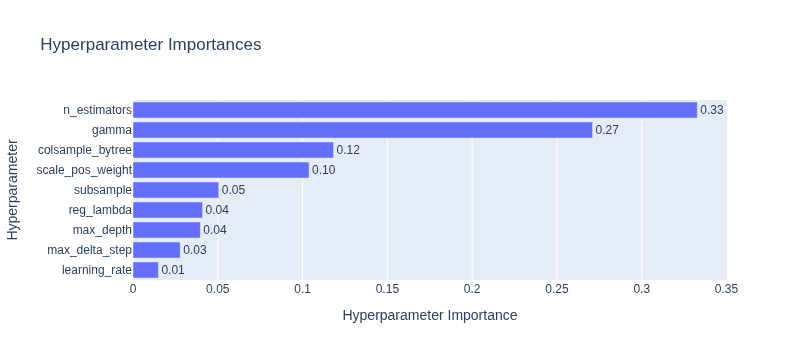

In [4]:
import optuna.visualization as vis

# Shows progress over time
fig = vis.plot_param_importances(study)
fig.show()

In [250]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import datasets

import numpy as np
import pandas as pd
import xgboost as xgb


from xgboost import XGBClassifier
from sklearn.model_selection import KFold, cross_val_score
from sklearn import metrics
# Create the training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
Best_params = study.best_params

# Instantiate the classifier: dt_clf_4
clf_1 = XGBClassifier(**Best_params)

# Fit the classifier to the training set
clf_1.fit(X_train,y_train)

# Predict the labels of the test set: y_pred_4
y_pred_1 = clf_1.predict(X_test)

p_m1 = clf_1.predict_proba(X_test)[:, 1]

# Compute the accuracy of the predictions: accuracy
accuracy_xgb = metrics.accuracy_score(y_test,y_pred_1)#float(np.sum(y_pred_4==y_test))/y_test.shape[0]
auc_score_xgb = metrics.roc_auc_score(y_test,y_pred_1)
F1_xgb = metrics.f1_score(y_test,y_pred_1)
recall_xgb = metrics.recall_score(y_test,y_pred_1)
precision_xgb = metrics.recall_score(y_test,y_pred_1)
bal_acc_xgb = metrics.balanced_accuracy_score(y_test,y_pred_1)
fpr, tpr, thresholds = metrics.roc_curve(y_test, p_m1)

# Calculate G-Mean: sqrt(TPR * (1 - FPR))
gmeans = np.sqrt(tpr * (1 - fpr))

# Locate the index of the largest g-mean
best_idx = np.argmax(gmeans)
best_threshold = thresholds[best_idx]

xgb_met = [accuracy_xgb,auc_score_xgb,F1_xgb,recall_xgb,precision_xgb]
# Cross validation
k_folds = KFold(n_splits = 5)
scores_1 = cross_val_score(clf_1, X, y, cv = k_folds)
print("Xval:", scores_1)
print("accuracy:", accuracy_xgb)
print("bal_acc:", bal_acc_xgb)
print("auc:", auc_score_xgb)
print("F1:", F1_xgb)
print("recall:", recall_xgb)
print("precision:", precision_xgb)
print("threshold:", best_threshold)
print(y_pred_1)

feat_imp = clf_1.get_booster().get_score(importance_type = "weight")
keys = list(feat_imp.keys())
values = list(feat_imp.values())

feat_imp_data = pd.DataFrame(data = values, index = keys, columns=["score"]).sort_values(by = "score", ascending = False)
feat_imp_data.to_csv('xgbt_feat_imp.csv')
#data.nlargest(60, columns = "score").plot(kind = "bar")

Xval: [0.97686375 0.96915167 0.75835476 0.66066838 0.76349614]
accuracy: 0.910958904109589
bal_acc: 0.8925729442970822
auc: 0.8925729442970822
F1: 0.7936507936507936
recall: 0.8620689655172413
precision: 0.8620689655172413
threshold: 0.12712331116199493
[0 1 1 0 1 0 1 0 0 1 0 0 1 1 1 1 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 0
 0 0 1 0 0 0 0 0 0 0 1 0 1 1 0 1 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 1 0 1 1 1 0 1 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 1 1 0 0 1
 0 1 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 1 0 1
 0 1 0 0 0 0 1 1 0 0 1 0 0 0 0 0 0 0 1 1 1 0 0 1 1 0 0 0 0 0 1 1 0 0 1 1 1
 0 0 1 0 1 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 1 0 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0 1
 0 0 0 1 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0
 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 

In [251]:
import shap
background = shap.maskers.Independent(X, max_samples=100)

# compute SHAP values
explainer = shap.Explainer(clf_1, background)
shap_values = explainer(X)

Background dataset has 1945 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1945 when initializing the masker.


In [252]:
# Set font sizes globally before calling the plot
plt.rcParams.update({'font.size': 14})
plt.rcParams.update({'axes.labelsize': 16})
plt.rcParams.update({'xtick.labelsize': 12})
plt.rcParams.update({'ytick.labelsize': 12})

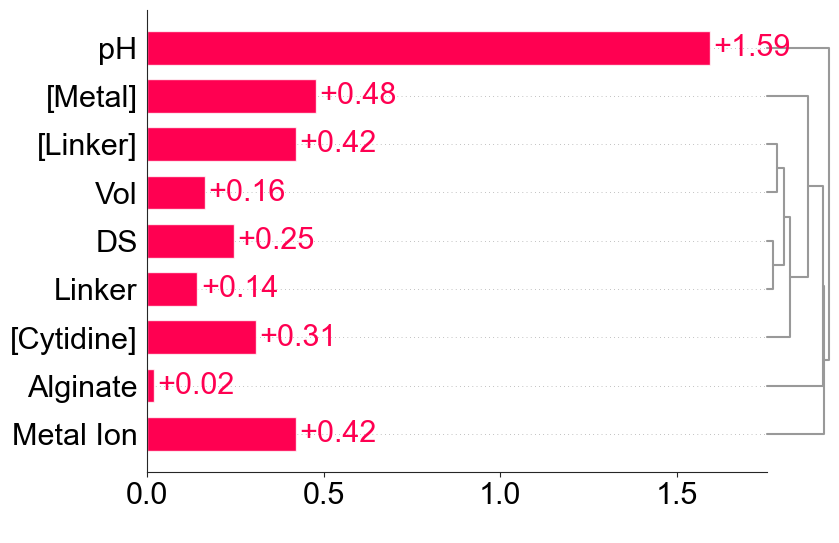

In [265]:
clust = shap.utils.hclust(X, y)

from matplotlib.ticker import FixedLocator


fig, ax = plt.subplots(figsize=(6, 6))
labels = ['Metal Ion','Alginate','[Cytidine]','Linker','DS','Vol','[Linker]','[Metal]','pH']

shap.plots.bar(shap_values, clustering=clust,clustering_cutoff=1.0, show=False)
# Match the number of labels you have
ax.yaxis.set_major_locator(FixedLocator([1, 2, 3, 4, 5, 6, 7, 8, 9]))
ax.set_yticklabels(labels)
ax.tick_params(axis='both',labelsize=22,labelcolor='black')

for text in ax.texts:
    text.set_visible(False)

for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.01, p.get_y() + p.get_height()/2, 
            f'+{width:.2f}', va='center', fontsize=22, color='#FF0051')

plt.xlabel(' ')

plt.savefig('figure/xgb_optimize/shap_optimized_features.png',dpi=600,transparent=False,bbox_inches='tight', pad_inches=0.2)
plt.show()

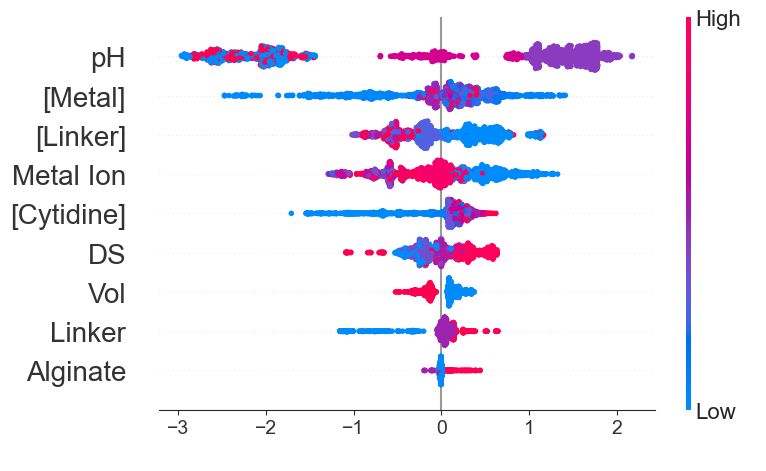

In [259]:
fig, ax = plt.subplots(figsize=(4, 2))
labels = ['Alginate','Linker','Vol','DS','[Cytidine]','Metal Ion','[Linker]','[Metal]','pH']
#values = [-3,-2,-1,0,1,2,3]
shap.plots.beeswarm(shap_values, show=False)

ax.set_yticklabels(labels, fontsize=20)
ax.tick_params(axis='x',labelsize=14)

cbar = plt.gcf().axes[-1]
cbar.set_ylabel(" ")
cbar.tick_params(labelsize=16)

plt.xlabel(' ')
plt.savefig('figure/xgb_optimize/shap_beeswarm_features.png',dpi=600,transparent=False,bbox_inches='tight', pad_inches=0.2)
plt.show()

In [260]:
from sklearn.metrics import roc_curve


X_val = pd.read_excel("C_Dataset_SHAP_Full_14-08-26.xlsx")
X_val = X_val.assign(Metal_Ion = encoder.fit_transform(X_val['Metal_Ion']))
X_val['Metal_Ion'] = encoder.fit_transform(X_val['Metal_Ion'])
X_val['Linker'] = encoder.fit_transform(X_val['Linker'])

X_val['Metal_Ion'] = X_val['Metal_Ion'].astype('category')
X_val['Linker'] = X_val['Linker'].astype('category')

y_val = X_val.Gel
X_val =  X_val.loc[:,'pH':'Alginate']

X_val = X_val.tail(100)

y_pred_val = clf_1.predict(X_val)
y_prob_val = clf_1.predict_proba(X_val)[:, 1]


X_val['probability'] = y_prob_val
X_val['actual'] = y_val

fpr, tpr, thresholds = roc_curve(X_val.actual,X_val.probability)

# Calculate G-Mean: sqrt(TPR * (1 - FPR))
gmeans = np.sqrt(tpr * (1 - fpr))

# Locate the index of the largest g-mean
best_idx = np.argmax(gmeans)
best_threshold = thresholds[best_idx]

print(best_threshold)

X_val['prediction'] = (y_prob_val >= best_threshold).astype(int)



acc_val = metrics.accuracy_score(X_val.actual,X_val.prediction)
F1_val = metrics.f1_score(X_val.actual,X_val.prediction)
print(f'accuracy score:{acc_val}')
print(f'F1 score:{F1_val}')

X_val.to_csv('predicted_val_set.csv', index=False)
X_val.head()

0.1832062155008316
accuracy score:0.91
F1 score:0.7567567567567568


,pH,Metal_Ion,Metal_Conc,Linker,Linker_Conc,Cytidine_Conc,DS,Vol,Alginate,probability,actual,prediction
1945,5.5,8,0.0125,5,0.0129,0.04788,13.8,0.5,0.0129,0.897207,1,1
1946,5.5,0,0.0125,5,0.0129,0.04788,13.8,0.5,0.0129,0.768001,1,1
1947,2.5,0,0.0125,5,0.0129,0.01596,13.8,0.5,0.0129,0.020939,0,0
1948,7.4,0,0.0250,5,0.0129,0.04788,13.8,0.5,0.0000,0.846663,0,1
1949,7.4,0,0.0500,5,0.0129,0.00798,13.8,0.5,0.0000,0.770201,1,1


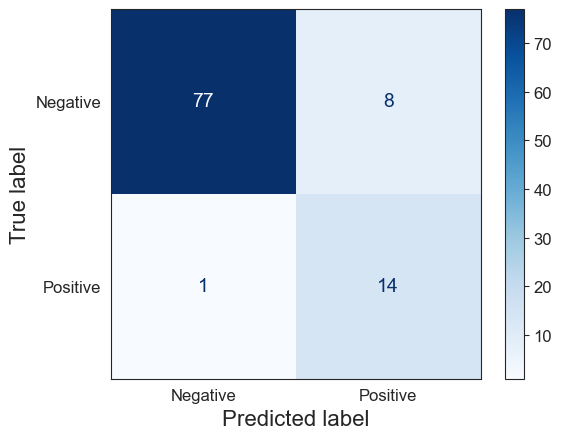

In [261]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm = confusion_matrix(X_val.actual,X_val.prediction)

# Display the matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [237]:
import pandas as pd
import numpy as np
from sklearn import preprocessing
from sklearn.model_selection import cross_val_score, train_test_split
encoder = preprocessing.LabelEncoder()

data = pd.read_excel("C_Dtst_Final_Data_Full_14-08-26.xlsx")

# transformation of variables
data = data.assign(Metal_Ion = encoder.fit_transform(data['Metal_Ion']))
data['Metal_Ion'] = encoder.fit_transform(data['Metal_Ion'])
data['Linker'] = encoder.fit_transform(data['Linker'])

data['Metal_Ion'] = data['Metal_Ion'].astype('category')
data['Linker'] = data['Linker'].astype('category')
#data['log_t'] = np.log1p(data['Time_m'])
#data['log_Alg_3APBA'] = 1/(1 + np.exp(-(data['Alg-3APBA'])))

# remove unwanted variables
data.pop('doi')
data.pop('mol')
data.pop('smiles')

data.head()

,Unnamed: 0,Unnamed: 1,Title,Gel,pH,Metal_Ion,Metal_Conc,Linker,Linker_Conc,Cytidine_Conc,DS,Vol,Alginate,Time_m
0,NaN,NaN,Nucleoside-Derived Metallohydrogel Induces Cel...,1,5.5,0,0.490,7,0.123,0.123,0.0,1.0,0.0,30
1,NaN,NaN,NaN,1,5.5,0,0.246,7,0.123,0.123,0.0,1.0,0.0,15
2,NaN,NaN,NaN,1,5.5,0,0.164,7,0.123,0.123,0.0,1.0,0.0,10
3,NaN,NaN,NaN,1,5.5,0,0.123,7,0.123,0.123,0.0,1.0,0.0,10
4,NaN,NaN,NaN,0,2.5,0,0.490,7,0.123,0.123,0.0,1.0,0.0,0


In [238]:
X = data.loc[:,'pH':'Alginate']
#y = np.log1p(data['Time_m'])
y = data['Time_m']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, shuffle=True)
#X100 = shap.utils.sample(X, 100)

print(X_train.shape,y_train.shape)
print(X_test.shape,y_test.shape)


(1361, 9) (1361,)
(584, 9) (584,)


In [239]:
import optuna
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score

def objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 10),
        #'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10),
        'random_state': 42
    }
    
    # Use XGBRegressor for regression tasks
    rgr_1 = xgb.XGBRegressor(**params, objective='reg:squarederror',tree_method='hist',enable_categorical=True)

    rgr_1.fit(X_train,y_train)

    # Predict the labels of the test set: y_pred_4
    y_pred_1 = rgr_1.predict(X_test)
    
    # Using negative MSE for cross-validation to maximize the score
    mse_xgb = metrics.mean_squared_error(y_test,y_pred_1)#float(np.sum(y_pred_4==y_test))/y_test.shape[0]
    rmse_xgb = np.sqrt(mse_xgb)
    r2_score = metrics.r2_score(y_test,y_pred_1)

    trial.set_user_attr("y_pred", y_pred_1)
    trial.set_user_attr("mse", mse_xgb)
    trial.set_user_attr("r2", r2_score)

    #score = cross_val_score(rgr_1, X, y, n_jobs=-1, cv=3, scoring='neg_mean_squared_error').mean()
    
    return r2_score

# 'maximize' works because we are returning a negative error (e.g., -10 is better than -50)
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=150)

errors = []
preds = []
for trial in study.trials:
    preds.append(trial.user_attrs["y_pred"])
    errors.append({
        "trial_number": trial.number,
        "mse": trial.user_attrs["mse"],
        "r2": trial.user_attrs["r2"]
    })

# Convert to DataFrame for easy analysis
trial_errors = pd.DataFrame(errors)
#print(df_results.head())

np.save('preds.npy', np.array(preds, dtype=object), allow_pickle=True)
trial_errors.to_csv('trial_errors_r2.csv', index=False)

print("Best params:", study.best_params)

[I 2026-09-23 15:48:32,700] A new study created in memory with name: no-name-b0775ccc-85f3-4176-aa80-aab4c027cca5
[I 2026-09-23 15:48:32,873] Trial 0 finished with value: 0.13637840747833252 and parameters: {'max_depth': 5, 'gamma': 4.75357153204958, 'reg_lambda': 7.319939418114051, 'learning_rate': 0.07661100707771368, 'n_estimators': 240, 'subsample': 0.5779972601681014, 'colsample_bytree': 0.5290418060840998, 'scale_pos_weight': 8.795585311974417, 'max_delta_step': 6}. Best is trial 0 with value: 0.13637840747833252.
[I 2026-09-23 15:48:33,167] Trial 1 finished with value: 0.23757582902908325 and parameters: {'max_depth': 8, 'gamma': 0.10292247147901223, 'reg_lambda': 9.699098521619943, 'learning_rate': 0.16967533607196555, 'n_estimators': 291, 'subsample': 0.5909124836035503, 'colsample_bytree': 0.5917022549267169, 'scale_pos_weight': 3.7381801866358395, 'max_delta_step': 5}. Best is trial 1 with value: 0.23757582902908325.
[I 2026-09-23 15:48:33,427] Trial 2 finished with value: 0

Best params: {'max_depth': 4, 'gamma': 4.589943980324029, 'reg_lambda': 2.0726233905276894, 'learning_rate': 0.20113642923445593, 'n_estimators': 909, 'subsample': 0.9995534801234836, 'colsample_bytree': 0.6719075594127435, 'scale_pos_weight': 9.521784897928274, 'max_delta_step': 10}


/home/lab/anaconda3/envs/ml_commons/lib/python3.14/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(


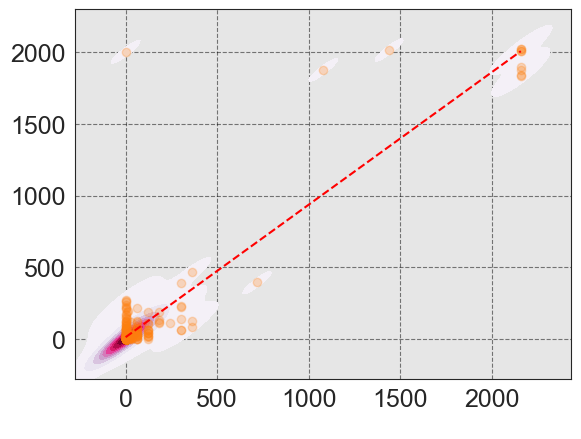

In [241]:
import seaborn as sb
from sklearn.preprocessing import RobustScaler

arr = np.load('preds.npy',allow_pickle='True').tolist()
eps = 1e-3

lower, upper = np.percentile(y_test, [1, 98.8]) # 98-98.6
#x_winsorized = np.clip(y_test, lower, upper)
#y_winsorized = np.clip(arr[94], lower, upper)

#x= np.log(y_test+eps)
#y= np.log(np.array(arr[95])+eps)
#print(np.isnan(x).any(), np.isinf(x).any())

x = np.clip(y_test, lower, upper) #y_test
y = np.clip(arr[94], lower, upper) #arr[95]

slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)

fig, ax = plt.subplots()
sb.kdeplot(x=x,y=y,
           thresh=0.01, levels=10,
           fill= True,cmap='PuRd',linewidths=2)

plt.scatter(x,y,alpha=0.25)
plt.plot(x_line, slope * x_line + intercept, 'r--', label=f"y = {slope:.2f}x + {intercept:.2f}")
plt.xlabel(' ')
ax.set_facecolor('#E6E6E6')
ax.grid(color='black', linestyle='dashed',alpha=0.5)
ax.tick_params(axis='both',labelsize=18,)

plt.savefig('figure/xgb_optimize/corr_R2.png',dpi=600,transparent=False,bbox_inches='tight', pad_inches=0.2)
#plt.xlim(-5, 1000)
#plt.ylim(-5, 1000)

#sb.jointplot(x=np.log(y_test),y=np.log(arr[95]),kind='reg',marginal_kws={"fill": True})


In [166]:
print(x.min())

0


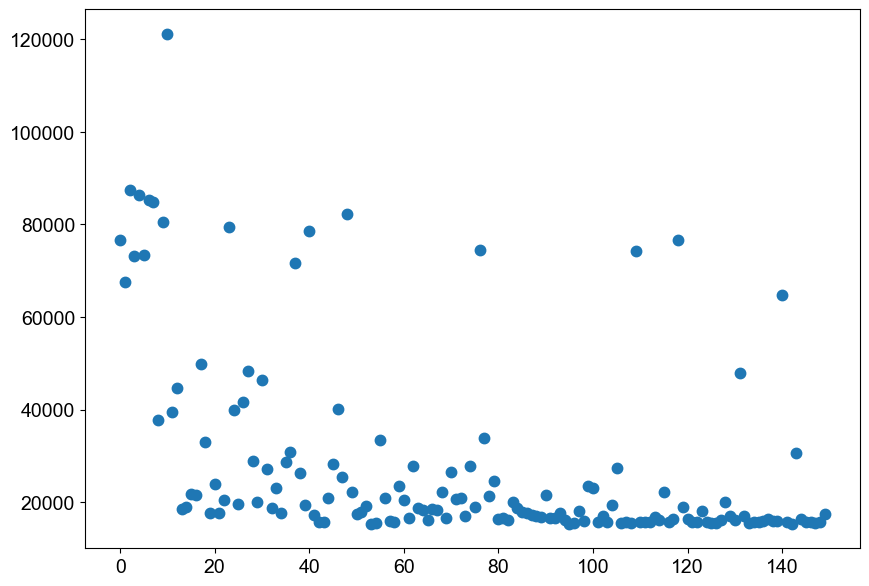

In [93]:
trial_errors = pd.read_csv('trial_errors_r2.csv')
trial_errors.head()

n_trials = trial_errors.trial_number

plt.figure(figsize=(10, 7))

plt.scatter(n_trials, trial_errors.r2, linewidth=2.5)
plt.tick_params(axis='y',which='both',labelsize=14)
plt.tick_params(axis='x',which='both',labelsize=14)

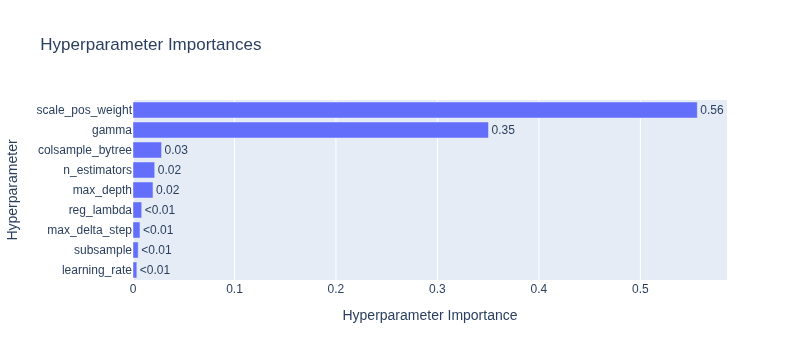

In [52]:
import optuna.visualization as vis

# Shows progress over time
fig = vis.plot_param_importances(study)
fig.show()

In [242]:
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn import metrics
import pickle


Best_params = study.best_params

# Instantiate the classifier: dt_clf_4
rgr_1 = XGBRegressor(**Best_params,objective='reg:squarederror',tree_method='hist', enable_categorical=True)


# Fit the classifier to the training set
rgr_1.fit(X_train,y_train)

# Predict the labels of the test set: y_pred_4
y_pred_1 = rgr_1.predict(X_test)
#y_val_pred = rgr_1.predict(X_val)

# Compute error metrics
mse_xgb = metrics.mean_squared_error(y_test,y_pred_1)#float(np.sum(y_pred_4==y_test))/y_test.shape[0]
rmse_xgb = np.sqrt(mse_xgb)
r2_score = metrics.r2_score(y_test,y_pred_1)

# store metrics
xgb_met = [mse_xgb,rmse_xgb,r2_score]

print("mse:", mse_xgb)
print("rmse:", rmse_xgb)
print("R2:", r2_score)
#print(y_pred_1)
ty = np.exp(y_pred_1)
#ty_val = np.exp(y_val_pred)
pred_1 = ["{:.10f}".format(x) for x in ty]
#pred_2 = ["{:.10f}".format(x) for x in ty_val]
#print(pred_2)

# SAVING MODEL

#pickle.dump(rgr_1,open("XGBT_rgr.pkl","wb"))

mse: 15326.71875
rmse: 123.80112580263558
R2: 0.8271874785423279


/tmp/ipykernel_3156378/1478336812.py:32: RuntimeWarning: overflow encountered in exp
  ty = np.exp(y_pred_1)


In [ ]:
X_val = pd.read_excel("Randomized_test_stability_v3-Validation-4-07-26.xlsx")
X_val = X_val.assign(Metal_Ion = encoder.fit_transform(X_val['Metal_Ion']))
X_val['Metal_Ion'] = encoder.fit_transform(X_val['Metal_Ion'])
X_val['Linker'] = encoder.fit_transform(X_val['Linker'])

y_val = X_val.Time_m
X_val =  X_val.loc[:,'pH':'Alginate']

X_val.head()

In [273]:
shap.initjs()
shap.force_plot(explainer_xgb.expected_value, shap_values_xgb.values[0, :], X_val.iloc[0, :])

NameError: name 'explainer_xgb' is not defined

In [281]:
X_val = pd.read_excel("C_Dtst_SHAP_Full_3-07-26.xlsx")
X_val = X_val.assign(Metal_Ion = encoder.fit_transform(X_val['Metal_Ion']))
X_val['Metal_Ion'] = encoder.fit_transform(X_val['Metal_Ion'])
X_val['Linker'] = encoder.fit_transform(X_val['Linker'])

X_val['Metal_Ion'] = X_val['Metal_Ion'].astype('category')
X_val['Linker'] = X_val['Linker'].astype('category')

y_val = np.log1p(X_val.Time_m)
X_val =  X_val.loc[:,'pH':'Additive']

X_val.tail(14)

,pH,Metal_Ion,Metal_Conc,Linker,Linker_Conc,Cytidine_Conc,DS,Vol,Additive
1548,5.5,8,0.01250,5,0.0129,0.04788,13.8,0.5,0.0129
1549,5.5,0,0.01250,5,0.0129,0.04788,13.8,0.5,0.0129
1550,2.5,0,0.01250,5,0.0129,0.01596,13.8,0.5,0.0129
1551,7.4,0,0.02500,5,0.0129,0.04788,13.8,0.5,0.0000
1552,7.4,0,0.05000,5,0.0129,0.00798,13.8,0.5,0.0000
1553,5.5,8,0.01250,5,0.0129,0.03192,13.8,0.5,0.0032
1554,5.5,8,0.02500,5,0.0129,0.03192,13.8,0.5,0.0000
1555,5.5,8,0.02500,5,0.0129,0.04788,13.8,0.5,0.0000
1556,5.5,8,0.05000,5,0.0129,0.00399,13.8,0.5,0.0064
1557,9.5,0,0.05000,5,0.0129,0.04788,13.8,0.5,0.0000


In [298]:
X_val = pd.read_excel("C_Dataset_SHAP_Full_14-08-26.xlsx")
X_val = X_val.assign(Metal_Ion = encoder.fit_transform(X_val['Metal_Ion']))
X_val['Metal_Ion'] = encoder.fit_transform(X_val['Metal_Ion'])
X_val['Linker'] = encoder.fit_transform(X_val['Linker'])

X_val['Metal_Ion'] = X_val['Metal_Ion'].astype('category')
X_val['Linker'] = X_val['Linker'].astype('category')
y_val = np.log1p(X_val.Time_m)
X_val =  X_val.loc[:,'pH':'Alginate']

X_val.tail(100)

,pH,Metal_Ion,Metal_Conc,Linker,Linker_Conc,Cytidine_Conc,DS,Vol,Alginate
1945,5.5,8,0.0125,5,0.01290,0.04788,13.8,0.5,0.0129
1946,5.5,0,0.0125,5,0.01290,0.04788,13.8,0.5,0.0129
1947,2.5,0,0.0125,5,0.01290,0.01596,13.8,0.5,0.0129
1948,7.4,0,0.0250,5,0.01290,0.04788,13.8,0.5,0.0000
1949,7.4,0,0.0500,5,0.01290,0.00798,13.8,0.5,0.0000
...,...,...,...,...,...,...,...,...,...
2040,5.5,8,0.0000,5,0.01277,0.00000,5.9,0.5,0.0000
2041,5.5,8,0.0000,5,0.01277,0.00000,5.9,0.5,0.0000
2042,9.5,0,0.0250,1,0.06100,0.06100,0.0,1.0,0.0000
2043,9.5,0,0.0250,1,0.06100,0.06100,0.0,1.0,0.0000


In [292]:
def find_text_objects(artist, depth=0):
    if isinstance(artist, plt.Text):
        print(f"Found Text at depth {depth}: '{artist.get_text()}'")
        # Try to hide it if it matches
        if "E[f(x)]" in artist.get_text() or "f(x)" in artist.get_text():
            artist.set_visible(False)
            print(" -> Hidden!")
            
    # Check children
    if hasattr(artist, 'get_children'):
        for child in artist.get_children():
            find_text_objects(child, depth + 1)

def hide_specific_annotations(artist):
    # Check if the artist is a Text object (includes Annotations)
    if isinstance(artist, plt.Text):
        text_content = artist.get_text()
        # Look for the exact string, handling potential extra whitespace/newlines
        if "E[f(X)]" in text_content or "f(x)" in text_content:
            artist.set_visible(False)
        if "= 0.917" in text_content:
            artist.set_visible(False)
            
    # Recursively check children
    if hasattr(artist, 'get_children'):
        for child in artist.get_children():
            hide_specific_annotations(child)

In [27]:
X_val.iloc[1200]

pH                5.50000
Metal_Ion         0.00000
Metal_Conc        0.02500
Linker            5.00000
Linker_Conc       0.01290
Cytidine_Conc     0.00798
DS               13.80000
Vol               0.50000
Additive          0.00000
Name: 1200, dtype: float64

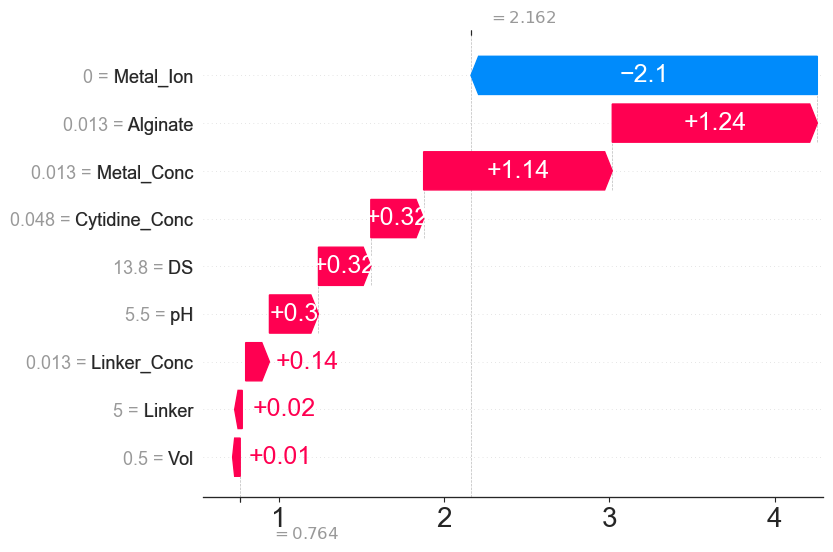

In [300]:
# 2. Initialize the TreeExplainer
import shap

fig, ax = plt.subplots(figsize=(4,4))


explainer = shap.TreeExplainer(rgr_1)

# 3. Calculate SHAP values for your dataset
# Use the training set or a representative sample
shap_values = explainer.shap_values(X_val)

# B. Waterfall plot (individual prediction explanation)
shap.plots.waterfall(shap.Explanation(values=shap_values[1946], 
                                      base_values=explainer.expected_value, 
                                      data=X_val.iloc[1946]),show=False)

ax.tick_params(axis='x',labelsize=20)
    

for text in ax.texts:
    text.set_fontsize(18)

hide_specific_annotations(fig)
plt.savefig('figure/xgb_optimize/regression_feat_contrib_worst.png',dpi=600,transparent=False,bbox_inches='tight', pad_inches=0.2)
plt.show()

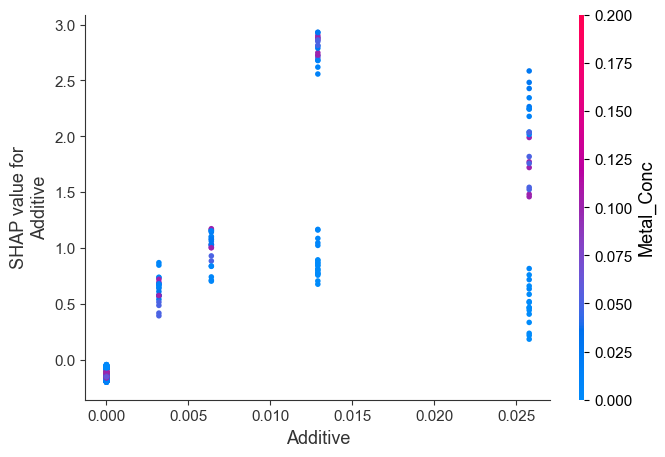

In [122]:
import shap

# Calculate SHAP values if you haven't already
explainer = shap.TreeExplainer(rgr_1)
shap_values = explainer.shap_values(X)

# Plot the effect for a specific feature (e.g., 'Metal_Ion')
# SHAP automatically colors by the feature it thinks is most correlated
shap.dependence_plot("Additive", shap_values, X)

In [85]:
from PyALE import ale

# Plot the ALE effect for your feature
ale_eff = ale(X=X_train, model=rgr_1, feature=["Metal_Ion"], grid_size=50)

PyALE._ALE_generic:INFO: Discrete feature detected.
